# Nucleus Segmentation Post-processing with RankSEG

Click to open in: \[[GitHub](https://github.com/TissueImageAnalytics/tiatoolbox/blob/develop/examples/13-rankseg-postprocessing.ipynb)\]\[[Colab](https://colab.research.google.com/github/TissueImageAnalytics/tiatoolbox/blob/develop/examples/13-rankseg-postprocessing.ipynb)\]



## About this notebook

Learn to use [RankSEG](https://github.com/rankseg/rankseg) as an optional decoder
alongside TIAToolbox. Run this notebook in Colab or in a local Jupyter environment
set up with the [installation guide](https://tia-toolbox.readthedocs.io/en/latest/installation.html).



## About this demo

Compare argmax and RankSEG using the **same MicroNet probabilities**, without
retraining. We use a CoNSeP-trained model to segment nuclei in a Kumar test image.

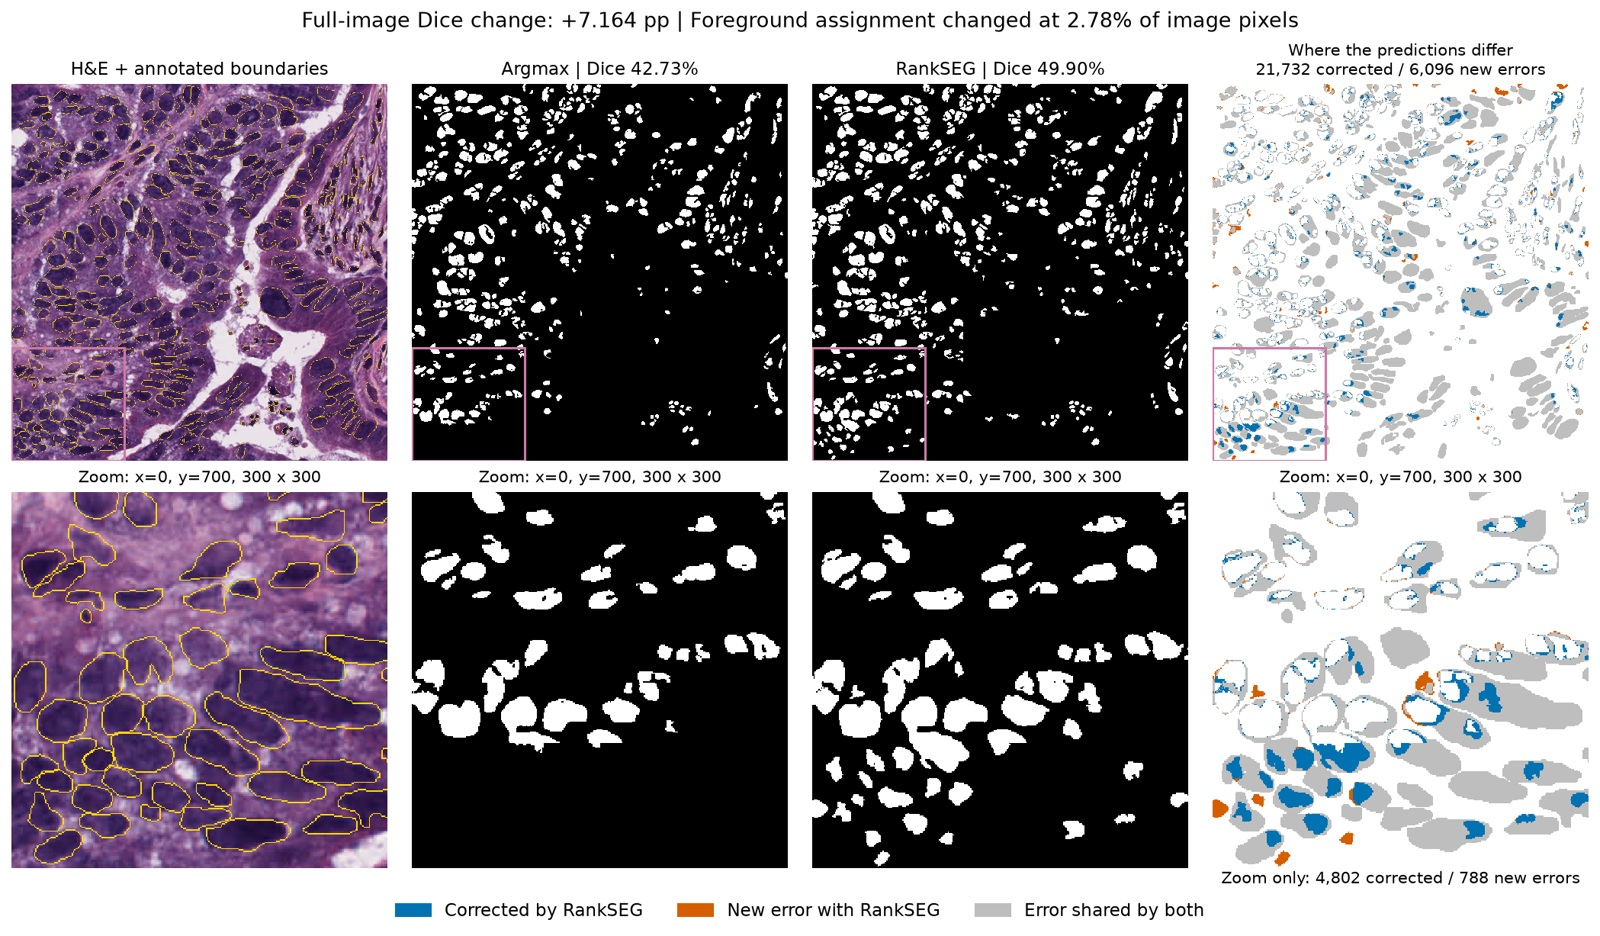

*Preview: foreground Dice improves from **42.73% to 49.90%** on
`TCGA-NH-A8F7-01A-01-TS1`. This favorable example was selected after inspecting
all 14 test images; full-cohort results are included below.*

The following steps reproduce the comparison:

**Image → MicroNet → shared probabilities → argmax / RankSEG
→ instance postprocessing → foreground Dice.**



## Setting up the environment

### TIAToolbox and dependencies installation

Install the packages below. Skip this cell if they are already installed.



In [ ]:
import sys

if "google.colab" in sys.modules:
    !apt-get -y install libopenjp2-7-dev libopenjp2-tools libpixman-1-dev

%pip install -q "tiatoolbox==2.1.3" "rankseg==0.0.8" "gdown==6.4.2"

> **IMPORTANT:** After installing packages in Colab, restart the session
> (*Runtime → Restart session*), then run the remaining cells in order.



### Importing related libraries



In [1]:
import logging
import warnings
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import zarr
from IPython.display import display as show
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from rankseg.functional import rankseg
from scipy.io import loadmat
from skimage.segmentation import find_boundaries

from tiatoolbox import logger, rcParam
from tiatoolbox.models.architecture.micronet import MicroNet
from tiatoolbox.models.engine.multi_task_segmentor import MultiTaskSegmentor
from tiatoolbox.utils.metrics import dice
from tiatoolbox.utils.misc import download_data

# Use a white background so figures also remain readable in dark mode.
plt.rcParams["figure.dpi"] = 300
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["font.size"] = 11

# Hide routine engine logs and two metadata notices emitted before manual mpp
# is applied to these image tiles. Other warnings and errors remain visible.
logger.setLevel(logging.WARNING)
logger.addFilter(
    lambda record: (
        record.module != "wsimeta"
        or record.getMessage()
        not in {"Raw data is None.", "Unknown scale (no objective_power or mpp)"}
    )
)
# Dask automatically rechunks these arrays when saving them to Zarr.
warnings.filterwarnings(
    "ignore",
    message=r"The array uses irregular chunk sizes\.",
    category=UserWarning,
    module=r"dask\.array\.core",
)

### GPU or CPU runtime

In Colab, select *Runtime → Change runtime type* to enable a GPU.



In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
rcParam["torch_compile_mode"] = "disable"
torch.set_num_threads(4)
_ = torch.manual_seed(0)

### Downloading the required files

Download the pretrained MicroNet model and the test images with nucleus
annotations from the [Kumar dataset](https://github.com/vqdang/hover_net#datasets).



In [3]:
work_dir = Path("tmp/rankseg").resolve()
data_dir = work_dir / "kumar"
folders = {
    "test_same/Images": "1HG7h0aL-sRjvHL-Fj2q_e6tCZ-fUkbaJ",
    "test_same/Labels": "1XwjdZBe53BX3v-MEPp8OceHEQVl3wyFi",
    "test_diff/Images": "1gUjPhJBCUUD0Y7yzyevtEIgT_Fq-pORc",
    "test_diff/Labels": "1FxmqAG2zkksUrH0l9LivymIpZSeJV-tG",
}
for folder, folder_id in folders.items():
    pattern = "*.tif" if folder.endswith("Images") else "*.mat"
    cached = list((data_dir / folder).glob(pattern))
    expected = 8 if folder.startswith("test_same") else 6
    if len(cached) == expected and all(path.stat().st_size > 0 for path in cached):
        continue
    gdown.download_folder(
        id=folder_id, output=str(data_dir / folder), quiet=True, resume=True
    )

cases = {
    f"{path.parent.parent.name}__{path.stem}": (
        path,
        path.parent.parent / "Labels" / f"{path.stem}.mat",
    )
    for path in sorted(data_dir.glob("test_*/Images/*.tif"))
}
np.testing.assert_equal(len(cases), 14)
np.testing.assert_equal(
    all(label.is_file() for _, label in cases.values()), desired=True
)

In [4]:
checkpoint_url = (
    "https://huggingface.co/TIACentre/TIAToolbox_pretrained_weights/resolve/"
    "ea909bdcce3aa409bf436c09b4495cca90a8e99b/micronet-consep.pth"
)
checkpoint = download_data(checkpoint_url, work_dir / "micronet-consep.pth")
selected_case = "test_diff__TCGA-NH-A8F7-01A-01-TS1"
image_path, label_path = cases[selected_case]
image = np.asarray(Image.open(image_path).convert("RGB"))

## Nucleus segmentation using the pretrained MicroNet model

Use `return_probabilities=True` to retain the probability maps from
`MultiTaskSegmentor`. MicroNet already returns normalized **background and
nucleus probabilities**, ready for decoding.



In [5]:
engine = MultiTaskSegmentor(
    model="micronet-consep",
    weights=checkpoint,
    batch_size=4,
    num_workers=0,
    device=device,
    verbose=False,
)

# Make MicroNet's existing NCHW channel softmax explicit.
for layer in engine.model.modules():
    if isinstance(layer, torch.nn.Softmax) and layer.dim is None:
        layer.dim = 1

In [6]:
def infer_image(path: Path) -> tuple[np.ndarray, np.ndarray]:
    """Run the registered pipeline and retrieve its two saved outputs."""
    outputs = engine.run(
        images=[path],
        patch_mode=False,
        save_dir=work_dir / "inference" / path.stem,
        overwrite=True,
        auto_get_mask=False,
        wsireader_kwargs={"mpp": 0.25},
        return_probabilities=True,
        return_predictions=(True,),
        output_type="zarr",
    )
    group = zarr.open(outputs[path], mode="r")
    probabilities = np.asarray(group["probabilities"]["0"])
    official_instances = np.asarray(group["predictions"])
    if (
        probabilities.shape != (*official_instances.shape, 2)
        or not np.isfinite(probabilities).all()
        or probabilities.min() < 0
        or probabilities.max() > 1
    ):
        message = "Expected finite H x W x 2 probabilities in [0, 1]."
        raise ValueError(message)
    np.testing.assert_allclose(probabilities.sum(axis=-1), 1, atol=1e-5, rtol=0)
    return probabilities, official_instances

In [7]:
probabilities, official_instances = infer_image(image_path)
np.testing.assert_equal(probabilities.shape[:2], image.shape[:2])

## Foreground decoding with RankSEG

RankSEG uses the full-image foreground probabilities to optimize expected Dice.
The input shape is `[batch, channels, height, width]`. Here `multilabel` decodes
one nucleus foreground channel.



In [8]:
def decode_foreground(probabilities: np.ndarray) -> np.ndarray:
    """Decode the full-image foreground probabilities with RankSEG."""
    foreground = torch.from_numpy(probabilities[..., 1].copy())[None, None]
    with torch.inference_mode():
        decoded = rankseg(
            foreground.to(device),
            metric="dice",
            solver="RMA",
            output_mode="multilabel",
            safe_screening=True,
            pruning_prob=0.5,
            smooth=0,
        )
    return decoded[0, 0].cpu().numpy().astype(bool)


argmax_mask = probabilities.argmax(axis=-1).astype(bool)
rankseg_mask = decode_foreground(probabilities)

### Applying the official instance postprocessor

Pass both decoded masks through MicroNet's instance postprocessor to produce
instance labels.



In [9]:
postprocessor = MicroNet()


def postprocess_mask(mask: np.ndarray) -> np.ndarray:
    """Apply official MicroNet instance extraction to a decoded mask."""
    one_hot = np.stack((~mask, mask), axis=-1).astype(np.uint8)
    return postprocessor.postproc([one_hot], verbose=False)[0]["predictions"]


argmax_instances = postprocess_mask(argmax_mask)
np.testing.assert_array_equal(argmax_instances, official_instances)
rankseg_instances = postprocess_mask(rankseg_mask)

## Evaluating foreground Dice

Compute foreground Dice on the **full image after instance postprocessing**
using TIAToolbox's `dice` function. Both false positives and false negatives
contribute to the score.



In [10]:
truth_instances = loadmat(label_path)["inst_map"]
np.testing.assert_equal(truth_instances.shape, image.shape[:2])
scores = pd.DataFrame(
    {
        "Argmax": [dice(truth_instances > 0, argmax_instances > 0)],
        "RankSEG": [dice(truth_instances > 0, rankseg_instances > 0)],
    },
    index=["Dice"],
)
scores["Change (pp)"] = 100 * (scores["RankSEG"] - scores["Argmax"])
show(
    scores.style.format(
        {"Argmax": "{:.3%}", "RankSEG": "{:.3%}", "Change (pp)": "{:+.3f}"}
    )
)

,Argmax,RankSEG,Change (pp)
Dice,42.735%,49.899%,+7.164


## Visualizing the predictions

The top row shows the full image; the bottom row zooms into the region with
the most prediction differences. All scores use the full image.

Yellow outlines mark annotated nuclei. In the change map, **blue** marks
corrected errors, **orange** new errors, and **gray** shared errors;
white means both predictions are correct. Change `zoom_x, zoom_y` to explore
another region.

Run this cell to draw the comparison for your selected image.



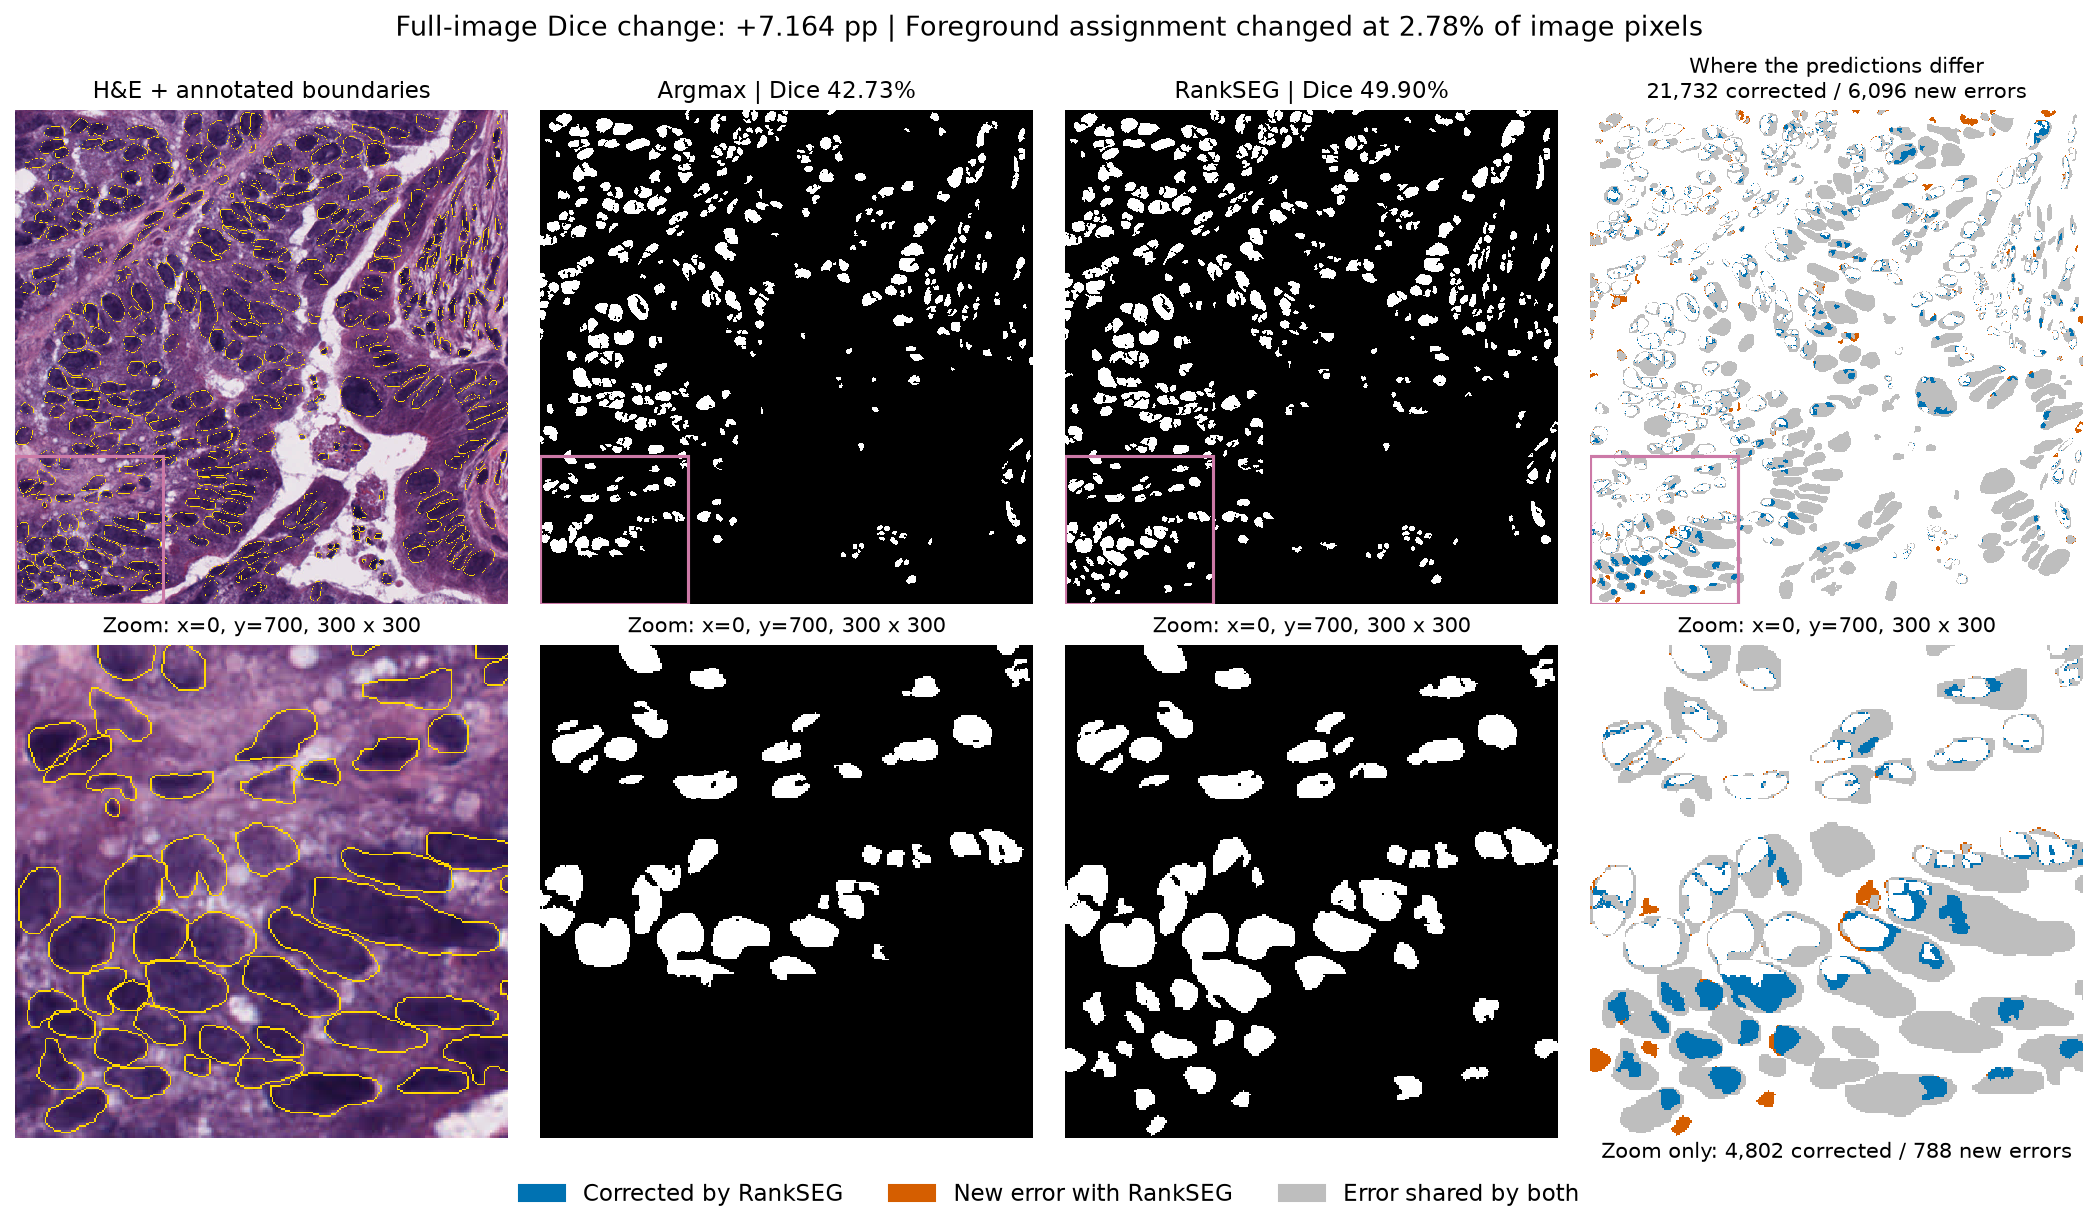

In [11]:
foreground_truth = truth_instances > 0
foreground_argmax = argmax_instances > 0
foreground_rankseg = rankseg_instances > 0
argmax_errors = foreground_argmax != foreground_truth
rankseg_errors = foreground_rankseg != foreground_truth
corrected = argmax_errors & ~rankseg_errors
introduced = ~argmax_errors & rankseg_errors
shared_errors = argmax_errors & rankseg_errors
changed = foreground_argmax != foreground_rankseg


size = 300
windows = (
    (x, y)
    for y in range(0, image.shape[0] - size + 1, 50)
    for x in range(0, image.shape[1] - size + 1, 50)
)
zoom_x, zoom_y = max(
    windows, key=lambda xy: changed[xy[1] : xy[1] + size, xy[0] : xy[0] + size].sum()
)
# Override zoom_x, zoom_y here to inspect another region.
# Colors retain shared errors; both beneficial and harmful changes
# receive equal visual emphasis. The full-image panels show every change.
change_map = np.ones((*foreground_truth.shape, 3), dtype=np.float32)
change_map[shared_errors] = np.array([190, 190, 190]) / 255
change_map[corrected] = np.array([0, 114, 178]) / 255
change_map[introduced] = np.array([213, 94, 0]) / 255
truth_overlay = image.astype(np.float32) / 255
truth_overlay[find_boundaries(truth_instances, mode="inner")] = (1, 0.85, 0)
panels = [truth_overlay, foreground_argmax, foreground_rankseg, change_map]
titles = [
    "H&E + annotated boundaries",
    f"Argmax | Dice {scores.loc['Dice', 'Argmax']:.2%}",
    f"RankSEG | Dice {scores.loc['Dice', 'RankSEG']:.2%}",
    "Where the predictions differ",
]


fig, axes = plt.subplots(2, 4, figsize=(14, 8.1), dpi=150, layout="constrained")
window = np.s_[zoom_y : zoom_y + size, zoom_x : zoom_x + size]
for column, (panel, title) in enumerate(zip(panels, titles, strict=True)):
    for row, visible in enumerate((panel, panel[window])):
        axes[row, column].imshow(
            visible, cmap="gray", vmin=0, vmax=1, interpolation="nearest"
        )
        axes[row, column].axis("off")
    axes[0, column].set_title(title, fontsize=11)
    axes[0, column].add_patch(
        Rectangle(
            (zoom_x, zoom_y), size, size, fill=False, edgecolor="#cc79a7", linewidth=1.5
        )
    )
    axes[1, column].set_title(
        f"Zoom: x={zoom_x}, y={zoom_y}, {size} x {size}", fontsize=10
    )
axes[0, 3].set_title(
    "Where the predictions differ\n"
    f"{corrected.sum():,} corrected / {introduced.sum():,} new errors",
    fontsize=10,
)
axes[1, 3].text(
    0.5,
    -0.04,
    f"Zoom only: {corrected[window].sum():,} corrected / "
    f"{introduced[window].sum():,} new errors",
    transform=axes[1, 3].transAxes,
    ha="center",
    fontsize=10,
)
fig.legend(
    handles=[
        Patch(color="#0072b2", label="Corrected by RankSEG"),
        Patch(color="#d55e00", label="New error with RankSEG"),
        Patch(color="#bebebe", label="Error shared by both"),
    ],
    loc="outside lower center",
    ncol=3,
    frameon=False,
)
gain = 100 * (scores.loc["Dice", "RankSEG"] - scores.loc["Dice", "Argmax"])
fig.suptitle(
    f"Full-image Dice change: {gain:+.3f} pp | "
    f"Foreground assignment changed at {changed.mean():.2%} of image pixels",
    fontsize=13,
)
fig.savefig(work_dir / "comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Optional: evaluation on all Kumar test images

Recorded results for all 14 test images:

| Metric          |  Argmax | RankSEG | Change (pp) | Images improved |
| --------------- | ------: | ------: | ----------: | --------------: |
| Foreground Dice | 61.263% | 64.942% |      +3.678 |           14/14 |

Dice is calculated **per image, then averaged with equal weight**.
Run the cells below to recompute these results, display each image's
scores and their mean, and save the scores to CSV. Set
`run_full_cohort = False` to skip this section.



In [12]:
run_full_cohort = True
cohort_scores = None

if run_full_cohort:
    rows = []
    for case_id, (case_image, case_label) in cases.items():
        case_probs, case_official = infer_image(case_image)
        case_argmax = postprocess_mask(case_probs.argmax(axis=-1).astype(bool))
        np.testing.assert_array_equal(case_argmax, case_official)
        case_rankseg = postprocess_mask(decode_foreground(case_probs))
        case_truth = loadmat(case_label)["inst_map"]
        for method, prediction in (("Argmax", case_argmax), ("RankSEG", case_rankseg)):
            rows.append(
                {
                    "id": case_id,
                    "method": method,
                    "Dice": float(dice(case_truth > 0, prediction > 0)),
                }
            )
    cohort_scores = pd.DataFrame(rows)
    cohort_scores.to_csv(work_dir / "kumar_per_image.csv", index=False)

In [13]:
if cohort_scores is not None:
    paired = cohort_scores.pivot_table(index="id", columns="method", values="Dice")
    paired.loc["Mean"] = paired.mean()
    paired["Change (pp)"] = 100 * (paired["RankSEG"] - paired["Argmax"])
    show(
        paired.style.format(
            {"Argmax": "{:.3%}", "RankSEG": "{:.3%}", "Change (pp)": "{:+.3f}"}
        )
    )

method,Argmax,RankSEG,Change (pp)
id,,,
test_diff__TCGA-AY-A8YK-01A-01-TS1,34.995%,43.617%,+8.622
test_diff__TCGA-DK-A2I6-01A-01-TS1,27.006%,35.347%,+8.341
test_diff__TCGA-G2-A2EK-01A-02-TSB,50.875%,57.470%,+6.595
test_diff__TCGA-KB-A93J-01A-01-TS1,76.821%,79.165%,+2.344
test_diff__TCGA-NH-A8F7-01A-01-TS1,42.735%,49.899%,+7.164
test_diff__TCGA-RD-A8N9-01A-01-TS1,73.622%,76.580%,+2.958
test_same__TCGA-21-5784-01Z-00-DX1,67.834%,70.481%,+2.646
test_same__TCGA-21-5786-01Z-00-DX1,50.429%,54.375%,+3.945
test_same__TCGA-B0-5698-01Z-00-DX1,56.066%,60.127%,+4.061


## Summary

To try your own model, pass its full-image foreground probabilities to
`decode_foreground`, then apply the model's instance postprocessor.

This example evaluates one foreground class. Higher foreground Dice does not
necessarily mean better separation of individual nuclei; evaluate that
separately if your task requires instance segmentation.



## References

- [RankSEG package and documentation](https://github.com/rankseg/rankseg)
- [RankSEG: a consistent ranking-based framework for segmentation (JMLR)](https://www.jmlr.org/papers/v24/22-0712.html)
- [TIAToolbox pretrained models](https://tia-toolbox.readthedocs.io/en/latest/pretrained.html)
- [Kumar test data provided by HoVer-Net](https://github.com/vqdang/hover_net#datasets)
- [Kumar et al., a dataset and technique for generalized nuclear segmentation](https://doi.org/10.1109/TMI.2017.2677499)

